# Step 8 — Game variant: the reward profile

**One dial moved, again.** Same agent, same $N=5$, same **ranked** seating, same
hyperparameters, same budget, same seeds. The only difference between the two runs below is
which of the two reward tables the environment pays out of.

**Why this control is not optional.** Every result up to step 7 used `terminal` — $+1$ for
winning, nothing otherwise — because that is the objective folder 02's mathematics actually
solves. But it is a hard signal to learn from: it arrives once, at the end, and only for one
player. `shaped` adds hints along the way: a bonus for a kill, a penalty for being
eliminated, a trickle for staying alive.

**Hints change what is being maximised.** So if survival of the weakest appears under
`shaped` but not under `terminal`, it is an artefact of the hints rather than a property of
the game. This step runs both and finds out.

**The mistake this step is designed to prevent.** The exact profile from folder 02 is a set
of *survival probabilities* — the answer to "who wins how often" and to nothing else. Under
`shaped` the agent is maximising a different quantity, so holding its numbers against the
exact profile would be grading it on an objective it was never given. As in step 7, the
code refuses.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from gruel_env import (GruelEnv, MISS, SHOOT_LEFT, SHOOT_RIGHT, N_ACTIONS,
                       REWARD_PROFILES)

N_PLAYERS = 5
SEED = 0

torch.set_num_threads(1)

EXACT_RANKED = {0.4: 0.24959, 0.5: 0.21073, 0.6: 0.17970, 0.7: 0.16194, 0.8: 0.19804}
UNIFORM = 1.0 / N_PLAYERS

print("torch", torch.__version__)
print("uniform share, 1/N:", UNIFORM)

torch 2.2.2
uniform share, 1/N: 0.2


## What the two profiles pay

The profiles are a table in the environment, so this reads them out rather than restating
them. A restated constant is a constant that can drift.

In [2]:
for reward_name in ["terminal", "shaped"]:
    print(reward_name + ":")
    for term in ["win", "eliminated", "kill", "survive"]:
        print("    %-12s %+.3f" % (term, REWARD_PROFILES[reward_name][term]))
    print()

print("`terminal` is `shaped` with the three hint terms set to zero.")

terminal:
    win          +1.000
    eliminated   +0.000
    kill         +0.000
    survive      +0.000

shaped:
    win          +1.000
    eliminated   -1.000
    kill         +0.100
    survive      +0.001

`terminal` is `shaped` with the three hint terms set to zero.


## Can a player do better by hunting than by winning?

This is the worry that makes the control necessary, and it is worth settling with
arithmetic before spending any compute on it.

**A non-winner can bank at most $N-2$ kills.** Killing $N-1$ opponents would leave it the
sole survivor — which makes it the winner, not a non-winner. So the most a player can take
from the kill term *while still losing* is $(N-2) \times 0.1$.

In [3]:
shaped = REWARD_PROFILES["shaped"]

max_kills_while_still_losing = N_PLAYERS - 2
gross_kill_reward = max_kills_while_still_losing * shaped["kill"]
best_non_winner = gross_kill_reward + shaped["eliminated"]

# A winner who kills nobody: everyone else's shots happened to do the work.
worst_winner = shaped["win"]

print("at N =", N_PLAYERS, "under `shaped`, ignoring the survival trickle for now")
print()
print("  the best a NON-WINNER can do")
print("      %d kills x %+.3f       = %+.4f"
      % (max_kills_while_still_losing, shaped["kill"], gross_kill_reward))
print("      eliminated            = %+.4f" % shaped["eliminated"])
print("      total                 = %+.4f" % best_non_winner)
print()
print("  the worst a WINNER can do")
print("      win, having killed nobody = %+.4f" % worst_winner)
print()
print("  can hunting out-pay winning?", best_non_winner > worst_winner)

at N = 5 under `shaped`, ignoring the survival trickle for now

  the best a NON-WINNER can do
      3 kills x +0.100       = +0.3000
      eliminated            = -1.0000
      total                 = -0.7000

  the worst a WINNER can do
      win, having killed nobody = +1.0000

  can hunting out-pay winning? False


**The gross kill reward is the number worth being careful about.** At larger $N$ it grows —
at $N=15$ a non-winner can reach $13 \times 0.1 = 1.3$, which exceeds the win reward of
$1.0$ **on the kill term alone**, and that comparison is often quoted as if it showed that
shaping makes losing pay better than winning. It does not, because the same profile charges
the victim $-1.0$ for being eliminated, and the elimination is certain: a player that
banked those kills and still lost is dead by definition.

In [4]:
print("%-6s %-14s %-14s %-16s %s"
      % ("N", "max kills", "gross kill pay", "net of the -1.0", "beats a bare win of +1.0?"))
for n in [3, 5, 10, 15]:
    gross = (n - 2) * shaped["kill"]
    net = gross + shaped["eliminated"]
    print("%-6d %-14d %-14.4f %-16.4f %s"
          % (n, n - 2, gross, net, net > shaped["win"]))

print()
print("The gross column crosses 1.0 between N=10 and N=15. The net column never does.")
print("So what shaping changes is the GRADIENT, not which outcome pays best: a kill is a")
print("certain, immediate +0.1, while the win is distant and uncertain.")

N      max kills      gross kill pay net of the -1.0  beats a bare win of +1.0?
3      1              0.1000         -0.9000          False
5      3              0.3000         -0.7000          False
10     8              0.8000         -0.2000          False
15     13             1.3000         0.3000           False

The gross column crosses 1.0 between N=10 and N=15. The net column never does.
So what shaping changes is the GRADIENT, not which outcome pays best: a kill is a
certain, immediate +0.1, while the win is distant and uncertain.


### The one term without a fixed ceiling

`win`, `eliminated` and `kill` are all bounded by the rules of the game. The survival
trickle is not — it pays on every step a player is alive, so its bound comes from the
episode-length cap instead. Worth checking, because an unbounded term could overturn the
arithmetic above.

In [5]:
bound_game = GruelEnv(n=N_PLAYERS, reward="shaped", seating="ranked", seed=0)

print("hard cap on episode length      :", bound_game.max_steps, "steps")
largest_possible_trickle = bound_game.max_steps * shaped["survive"]
print("so the trickle cannot exceed    : %+.4f" % largest_possible_trickle)
print()
print("giving the non-winner every advantage and the winner none:")
print("    best non-winner + full trickle = %+.4f"
      % (best_non_winner + largest_possible_trickle))
print("    worst winner, no trickle       = %+.4f" % worst_winner)
print("    hunting still loses?            ",
      (best_non_winner + largest_possible_trickle) < worst_winner)
print()
print("That is the extreme case and it never occurs: reaching the cap needs ~1000 steps of")
print("near-total abstention, and no episode in this folder has ever reached it.")

hard cap on episode length      : 1000 steps
so the trickle cannot exceed    : +1.0000

giving the non-winner every advantage and the winner none:
    best non-winner + full trickle = +0.3000
    worst winner, no trickle       = +1.0000
    hunting still loses?             True

That is the extreme case and it never occurs: reaching the cap needs ~1000 steps of
near-total abstention, and no episode in this folder has ever reached it.


**Where this argument stops.** The bound is arithmetic, so it covers every episode that
could happen — but it is a statement about *totals*, and an agent does not choose totals.
It chooses actions, and a kill is worth $+0.1$ *now* against a win that is uncertain and
several decisions away. That is a real distortion which the arithmetic does not rule out,
and it is why the run below is still necessary.

## Survival is counted from survivors, never from rewards

Step 4 established this and under `shaped` it stops being a technicality. Reward and
survival are the same number under `terminal` and are **not** the same number under
`shaped`, so a survival measurement taken from rewards would silently change meaning
between the two arms — and the difference would read as a finding.

In [6]:
for reward_name in ["terminal", "shaped"]:
    check_game = GruelEnv(n=N_PLAYERS, reward=reward_name, seating="ranked", seed=4242)
    check_game.reset()
    print("%-9s reward_params: %s" % (reward_name, check_game.reward_params))

print()
print("`survival_by_accuracy` below counts the SURVIVOR of each episode and never reads a")
print("reward, so it measures the same quantity in both arms.")

terminal  reward_params: {'win': 1.0, 'eliminated': 0.0, 'kill': 0.0, 'survive': 0.0}
shaped    reward_params: {'win': 1.0, 'eliminated': -1.0, 'kill': 0.1, 'survive': 0.001}

`survival_by_accuracy` below counts the SURVIVOR of each episode and never reads a
reward, so it measures the same quantity in both arms.


## The agent, unchanged

Carried forward from step 7 without modification. **The observation contains no reward
information at all** — own accuracy, left, right, fraction alive. So the two arms below run
byte-identical networks on byte-identical inputs; the only thing that differs is the number
the optimiser is handed.

In [7]:
OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64


class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector

One thing the critic does get from this, worth noticing: `global_state` reads each
**position's** accuracy, so under random seating its input genuinely changes from episode
to episode. The critic is not being asked to memorise one board — it has to read the one
in front of it.

In [8]:
def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}
        # What each player had already banked when it made each decision. Needed because
        # the return for a decision is whatever arrives AFTER it, and under `shaped`
        # rewards arrive throughout the episode rather than only at the end.
        episode_banked_before = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            banked_so_far = float(game.episode_returns[acting_agent])
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)
            episode_banked_before[actor].append(banked_so_far)

            game.step(int(action))

        for position in range(game.n):
            # The return for a decision is the reward-to-go: everything this player ended
            # the episode with, minus what it had already banked when it decided. With a
            # discount of 1 that is exactly the undiscounted sum of what came after.
            #
            # Reading it from the environment is the whole point of this step. Assuming
            # `1.0 for the winner, 0.0 for everyone else` is correct under `terminal` and
            # silently WRONG under `shaped`, where it would discard every kill bonus,
            # every elimination penalty and every survival tick -- and both arms would then
            # train on identical numbers and look identical for a reason that is a bug.
            name = game.agent_of_position[position]
            final_total = float(game.episode_returns[name])
            for index in range(len(episode_actions[position])):
                own_return = final_total - episode_banked_before[position][index]
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch

In [9]:
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01
LEARNING_RATE = 0.003


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

## Measurement, carried forward

Note that `survival_by_accuracy` keys on **the player's accuracy**, never on its
position. Under random seating a position means nothing from one episode to the next, so
keying on position would produce five numbers all near $1/N$ and hide the entire effect.

In [10]:
def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy


def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        # What each player actually banked. Step 7 had no use for this; here it is the
        # whole question, because under `shaped` the reward is no longer just "did I win".
        banked = {}
        for position in range(game.n):
            name = game.agent_of_position[position]
            accuracy = round(float(game.accuracies[position]), 4)
            banked[accuracy] = float(game.episode_returns[name])

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "banked": banked,
            "decisions": decisions,
        })
    return records


def stagnation_rate(records):
    stagnated = 0
    for record in records:
        if record["stagnated"]:
            stagnated = stagnated + 1
    return stagnated / len(records)


def survival_by_accuracy(records, accuracies):
    wins = {}
    for accuracy in accuracies:
        wins[accuracy] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates


def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other


def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions


def targeting_by_alive(records):
    stronger_count = {}
    decision_count = {}
    for record in records:
        for decision in record["decisions"]:
            if not eligible(decision):
                continue
            alive_then = decision["n_alive"]
            if alive_then not in decision_count:
                stronger_count[alive_then] = 0
                decision_count[alive_then] = 0
            decision_count[alive_then] = decision_count[alive_then] + 1
            if chose_stronger(decision):
                stronger_count[alive_then] = stronger_count[alive_then] + 1
    rows = {}
    for alive in sorted(decision_count):
        rows[alive] = (stronger_count[alive] / decision_count[alive],
                       stronger_count[alive],
                       decision_count[alive])
    return rows



## The reward changes what the agent is told, not what the game does

This is the structural difference from step 7 and it is worth establishing before anything
is trained. Seating changed the *game*: it re-dealt the accuracies, so the two arms were
playing different situations. The reward profile changes only the numbers handed to the
optimiser — the dynamics, the accuracies, the turn order and the random stream are all
untouched.

Which gives a check with a known answer: **an untrained policy must produce identical play
under both profiles from the same seed**, because nothing it does depends on the reward.

In [11]:
def shoot_strongest(game, actor):
    left, right = game.neighbours(actor)
    if game.accuracies[left] >= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT


identical_play = {}
for reward_name in ["terminal", "shaped"]:
    probe_game = GruelEnv(n=N_PLAYERS, reward=reward_name, seating="ranked", seed=777)
    identical_play[reward_name] = play_episodes(probe_game, shoot_strongest, 200)

survivors_terminal = [r["survivor_accuracy"] for r in identical_play["terminal"]]
survivors_shaped = [r["survivor_accuracy"] for r in identical_play["shaped"]]

print("same policy, same seed, 200 episodes under each profile")
print("  identical sequence of winners? ", survivors_terminal == survivors_shaped)
print()
print("but what they were PAID differs:")
for reward_name in ["terminal", "shaped"]:
    totals = []
    for record in identical_play[reward_name]:
        totals.append(sum(record["banked"].values()))
    print("    %-9s mean total banked across all five players: %+.4f"
          % (reward_name, sum(totals) / len(totals)))

same policy, same seed, 200 episodes under each profile
  identical sequence of winners?  True

but what they were PAID differs:
    terminal  mean total banked across all five players: +1.0000
    shaped    mean total banked across all five players: -2.5788


**So the reward profile is a dial on learning, not on the game.** Any difference between the
two arms below has to have come through training, which is a narrower and cleaner claim than
step 7 could make.

## The numbers the optimiser actually sees

The environment computing a reward and the training loop *using* it are two different
things, and the gap between them is invisible in the output of a run. So it is checked
here, before any compute is spent: collect one small batch under each profile and look at
the returns.

**Under `terminal` there are only two possible returns** — you won or you did not — so the
set of distinct values must be exactly $\{0, 1\}$. That is also what steps 3 to 7 trained
on, so this doubles as a check that nothing about them has changed. **Under `shaped` a
spread of values must appear**, because kills, deaths and survival ticks land throughout
the episode. If both profiles produce the same two values, the hints are being discarded.

In [12]:
# Seeded before the network is built: its starting weights decide which actions
# the probe samples, and an unseeded generator differs in every fresh process.
torch.manual_seed(4321)
probe_model = SharedActorCritic(n_players=N_PLAYERS)

for reward_name in ["terminal", "shaped"]:
    torch.manual_seed(4321)
    probe_game = GruelEnv(n=N_PLAYERS, reward=reward_name, seating="ranked", seed=8888)
    probe_batch = collect_batch(probe_model, probe_game, 40)
    seen = sorted(set(round(float(r), 6) for r in probe_batch["returns"]))
    print("%-9s %4d decisions, %d distinct return values" % (reward_name,
                                                             len(probe_batch["returns"]),
                                                             len(seen)))
    if len(seen) <= 6:
        print("            values: %s" % seen)
    else:
        print("            range : %+.4f to %+.4f, e.g. %s"
              % (seen[0], seen[-1], [seen[0], seen[1], seen[len(seen) // 2], seen[-1]]))
    if reward_name == "terminal":
        terminal_values = seen
    else:
        shaped_values = seen
    print()

print("terminal returns are exactly {0.0, 1.0}:", terminal_values == [0.0, 1.0])
print("shaped returns differ from those        :", shaped_values != terminal_values)
print()
if terminal_values == [0.0, 1.0] and shaped_values != terminal_values:
    print("So the two arms will train on genuinely different numbers, and the terminal arm")
    print("trains on exactly what steps 3 to 7 did.")
else:
    print("STOP. The two profiles are not reaching the optimiser differently, so the two")
    print("arms below would differ in name only and any comparison would be empty.")

terminal   341 decisions, 2 distinct return values
            values: [0.0, 1.0]

shaped     341 decisions, 61 distinct return values
            range : -0.9990 to +1.4070, e.g. [-0.999, -0.998, -0.791, 1.407]

terminal returns are exactly {0.0, 1.0}: True
shaped returns differ from those        : True

So the two arms will train on genuinely different numbers, and the terminal arm
trains on exactly what steps 3 to 7 did.


## Why the returns are undiscounted

The returns above are **undiscounted** — a discount factor of $1$ — in both arms. The usual
reason to discount under `shaped` is specific: with a discount of $0.99$ and a survival
tick of $0.001$ the discounted stream caps at $0.001 / (1 - 0.99) = 0.1$, which keeps it
from rivalling the win reward. That reason is about a *cap*, so it is worth checking
whether the cap is anywhere near binding at this scale before importing the machinery.

In [13]:
length_game = GruelEnv(n=N_PLAYERS, reward="shaped", seating="ranked", seed=5000)
lengths = []
decisions_per_player = []
for _ in range(2000):
    length_game.reset()
    counts = {}
    for position in range(N_PLAYERS):
        counts[position] = 0
    steps_taken = 0
    for acting_agent in length_game.agent_iter():
        observation, reward, termination, truncation, info = length_game.last()
        if termination or truncation:
            length_game.step(None)
            continue
        actor = length_game.position_of_agent[acting_agent]
        counts[actor] = counts[actor] + 1
        length_game.step(shoot_strongest(length_game, actor))
        steps_taken = steps_taken + 1
    lengths.append(steps_taken)
    for position in counts:
        decisions_per_player.append(counts[position])

mean_length = sum(lengths) / len(lengths)
mean_decisions = sum(decisions_per_player) / len(decisions_per_player)

print("over 2000 episodes at N =", N_PLAYERS)
print("    mean episode length        : %.2f steps" % mean_length)
print("    longest episode seen       : %d steps" % max(lengths))
print("    mean decisions per player  : %.2f" % mean_decisions)
print("    most by any one player     : %d" % max(decisions_per_player))
print()
print("    ticks accrued in a mean episode : %.3f" % (mean_length * shaped["survive"]))
print("    the cap that 0.99 exists to impose:  0.100")
print("    the episode length that cap needs :", length_game.max_steps, "steps")
print()
print("So the survival stream accrues under a hundredth of the win reward here, against a")
print("cap of a tenth that it never approaches. Discounting would change the furthest")
print("return in a typical episode by about a percent, and it would add machinery whose")
print("only purpose is to bound something already small. Recorded as a deviation.")

over 2000 episodes at N = 5
    mean episode length        : 7.46 steps
    longest episode seen       : 24 steps
    mean decisions per player  : 1.49
    most by any one player     : 14

    ticks accrued in a mean episode : 0.007
    the cap that 0.99 exists to impose:  0.100
    the episode length that cap needs : 1000 steps

So the survival stream accrues under a hundredth of the win reward here, against a
cap of a tenth that it never approaches. Discounting would change the furthest
return in a typical episode by about a percent, and it would add machinery whose
only purpose is to bound something already small. Recorded as a deviation.


## The guard: the exact comparison refuses to run on the wrong objective

Step 7 keyed this on seating. Here it is keyed on the reward, for the same reason and with
the same mechanism: the README's warning is a function precondition rather than a note.

In [14]:
class WrongVariant(Exception):
    pass


def compare_to_exact(measured, reward_name):
    """Ratios against the exact profile. Only legitimate under the terminal reward."""
    if reward_name != "terminal":
        raise WrongVariant(
            "the exact profile is a set of SURVIVAL PROBABILITIES, computed for a game whose "
            "only payoff is winning; under " + reward_name + " the agent is also paid for kills, "
            "for staying alive and penalised for dying, so it is maximising a different "
            "quantity and these numbers are not its target")
    rows = []
    for accuracy in sorted(measured):
        rows.append((accuracy, measured[accuracy], EXACT_RANKED[accuracy],
                     measured[accuracy] / EXACT_RANKED[accuracy]))
    return rows

## Training: two profiles, three seeds each

In [15]:
UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
SEEDS = [0, 1, 2]
REWARDS = ["terminal", "shaped"]
SEATING = "ranked"

print("configurations :", REWARDS)
print("seeds each     :", SEEDS)
print("seating        :", SEATING, "(held fixed)")
print("per run        :", UPDATES * EPISODES_PER_UPDATE, "training episodes,",
      EVALUATION_EPISODES, "measured")
print("total runs     :", len(REWARDS) * len(SEEDS))

configurations : ['terminal', 'shaped']
seeds each     : [0, 1, 2]
seating        : ranked (held fixed)
per run        : 192000 training episodes, 10000 measured
total runs     : 6


## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [16]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step8_reward_profile.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [17]:
def train_one(reward_name, seed):
    torch.manual_seed(2000 + seed)
    model = SharedActorCritic(n_players=N_PLAYERS)
    training_game = GruelEnv(n=N_PLAYERS, reward=reward_name, seating=SEATING,
                             seed=1000 + seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(model, training_game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)

    measurement_game = GruelEnv(n=N_PLAYERS, reward=reward_name, seating=SEATING,
                                seed=5000 + seed)
    records = play_episodes(measurement_game, make_agent_policy(model),
                            EVALUATION_EPISODES)
    return model, records


results = {}
models = {}
for reward_name in REWARDS:
    for seed in SEEDS:
        started = time.time()
        model, records = train_one(reward_name, seed)
        results[(reward_name, seed)] = records
        save_model(model, run_key(N_PLAYERS, SEATING, reward_name, "centralised", UPDATES, seed),
                   mappo_settings(N_PLAYERS, reward_name, SEATING, seed, UPDATES, EPISODES_PER_UPDATE,
                                  "centralised", time.time() - started, "training and the 10,000-episode measurement"))
        models[(reward_name, seed)] = model
        print(reward_name, "seed", seed, "done")

print()
print("all", len(results), "runs trained")

terminal seed 0 done


terminal seed 1 done


terminal seed 2 done


shaped seed 0 done


shaped seed 1 done


shaped seed 2 done

all 6 runs trained


## Only one thing differed — checked, not asserted

As in step 7, the claim rests on the two arms being identical apart from the one dial, so
the two environments are compared attribute by attribute rather than trusted.

In [18]:
held_fixed = {
    "n": N_PLAYERS,
    "seating": SEATING,
    "updates": UPDATES,
    "episodes_per_update": EPISODES_PER_UPDATE,
    "learning_rate": LEARNING_RATE,
    "clip": CLIP,
    "epochs": EPOCHS,
    "entropy_coefficient": ENTROPY_COEFFICIENT,
    "evaluation_episodes": EVALUATION_EPISODES,
    "seeds": tuple(SEEDS),
}
for name in held_fixed:
    print("  held fixed: %-22s %s" % (name, held_fixed[name]))

print()
sample_terminal = GruelEnv(n=N_PLAYERS, reward="terminal", seating=SEATING, seed=1000)
sample_shaped = GruelEnv(n=N_PLAYERS, reward="shaped", seating=SEATING, seed=1000)

differences = []
for attribute in ["n", "reward_profile", "reward_params", "seating", "stagnation_rounds",
                  "max_steps"]:
    left_value = getattr(sample_terminal, attribute)
    right_value = getattr(sample_shaped, attribute)
    if left_value != right_value:
        differences.append(attribute)

print("environment attributes that differ between the two arms:")
for attribute in differences:
    print("   ", attribute)

  held fixed: n                      5
  held fixed: seating                ranked
  held fixed: updates                2000
  held fixed: episodes_per_update    96
  held fixed: learning_rate          0.003
  held fixed: clip                   0.2
  held fixed: epochs                 4
  held fixed: entropy_coefficient    0.01
  held fixed: evaluation_episodes    10000
  held fixed: seeds                  (0, 1, 2)

environment attributes that differ between the two arms:
    reward_profile
    reward_params


**Two attributes differ, and that is not two dials.** `reward_params` is a lookup of
`reward_profile` — the table, fetched by name — so it cannot be set independently and is not
a second thing that moved. Rather than quietly dropping it from the count, which would be
rigging the check to produce the answer it is supposed to test, that dependence is verified.

In [19]:
derived = []
for sample in [sample_terminal, sample_shaped]:
    derived.append(sample.reward_params == REWARD_PROFILES[sample.reward_profile])

print("reward_params equals REWARD_PROFILES[reward_profile] in both arms:", all(derived))
independent = []
for attribute in differences:
    if attribute != "reward_params":
        independent.append(attribute)
print("so the independent dials that moved:", independent)
print("count:", len(independent), "->",
      "exactly one dial moved" if len(independent) == 1 else "MORE THAN ONE THING MOVED")

reward_params equals REWARD_PROFILES[reward_profile] in both arms: True
so the independent dials that moved: ['reward_profile']
count: 1 -> exactly one dial moved


## Classify both arms first

Before any survival number is read, as step 4 established. An arm that stagnated is not
playing the game the exact answers describe.

In [20]:
STAGNATION_LIMIT = 0.01
accuracies = sorted(EXACT_RANKED)

print("%-10s %-6s %14s   %s" % ("reward", "seed", "stagnation", "class"))
for reward_name in REWARDS:
    for seed in SEEDS:
        stalled = stagnation_rate(results[(reward_name, seed)])
        if stalled <= STAGNATION_LIMIT:
            verdict = "shooting"
        else:
            verdict = "NON-shooting"
        print("%-10s %-6d %14.4f   %s" % (reward_name, seed, stalled, verdict))

reward     seed       stagnation   class
terminal   0              0.0000   shooting
terminal   1              0.0000   shooting
terminal   2              0.0000   shooting
shaped     0              0.0000   shooting
shaped     1              0.0000   shooting
shaped     2              0.0000   shooting


## The result: survival by accuracy, both arms

In [21]:
def pooled_survival(reward_name):
    totals = {}
    for accuracy in accuracies:
        totals[accuracy] = 0.0
    for seed in SEEDS:
        rates = survival_by_accuracy(results[(reward_name, seed)], accuracies)
        for accuracy in accuracies:
            totals[accuracy] = totals[accuracy] + rates[accuracy]
    for accuracy in accuracies:
        totals[accuracy] = totals[accuracy] / len(SEEDS)
    return totals


terminal_survival = pooled_survival("terminal")
shaped_survival = pooled_survival("shaped")

print("%-10s %9s %9s %9s %9s %9s   %s"
      % ("reward", "0.4", "0.5", "0.6", "0.7", "0.8", "weakest/uniform"))
for label, series in [("terminal", terminal_survival), ("shaped", shaped_survival)]:
    cells = []
    for accuracy in accuracies:
        cells.append(format(series[accuracy], ".4f"))
    print("%-10s %9s %9s %9s %9s %9s   %.3f"
          % (label, cells[0], cells[1], cells[2], cells[3], cells[4],
             series[0.4] / UNIFORM))
print("%-10s %9s %9s %9s %9s %9s"
      % ("uniform", format(UNIFORM, ".4f"), format(UNIFORM, ".4f"),
         format(UNIFORM, ".4f"), format(UNIFORM, ".4f"), format(UNIFORM, ".4f")))

reward           0.4       0.5       0.6       0.7       0.8   weakest/uniform
terminal      0.2431    0.2125    0.1855    0.1610    0.1979   1.215
shaped        0.2422    0.2148    0.1917    0.1618    0.1896   1.211
uniform       0.2000    0.2000    0.2000    0.2000    0.2000


## The arithmetic, now measured

The bound derived at the top said hunting cannot out-pay winning. That was a statement about
what is *possible*; this is what the trained agent actually banked, over 30,000 episodes of
the shaped arm.

In [22]:
best_seen_non_winner = None
worst_seen_winner = None
kills_by_the_best_non_winner = None

for seed in SEEDS:
    for record in results[("shaped", seed)]:
        winner = record["survivor_accuracy"]
        for accuracy in record["banked"]:
            total = record["banked"][accuracy]
            if accuracy == winner:
                if worst_seen_winner is None or total < worst_seen_winner:
                    worst_seen_winner = total
            else:
                if best_seen_non_winner is None or total > best_seen_non_winner:
                    best_seen_non_winner = total

print("measured over the shaped arm,", len(SEEDS) * EVALUATION_EPISODES, "episodes:")

# If no episode produced a sole survivor there is nothing to compare, and printing a
# verdict from missing data is worse than printing nothing. Same rule as targeting_rate,
# which returns None rather than 0.0 when it saw no decisions.
if best_seen_non_winner is None or worst_seen_winner is None:
    print("    NO DATA — every episode ended without a sole survivor, so there is no")
    print("    winner-against-non-winner comparison to make.")
    hunting_loses = None
else:
    print("    best total banked by a player that did NOT win : %+.4f"
          % best_seen_non_winner)
    print("    worst total banked by a player that DID win    : %+.4f" % worst_seen_winner)
    print()
    # Two bounds, because they answer different questions and mixing them up is easy:
    # the kill-and-death terms alone, and those plus every survival tick the episode cap
    # allows. The measured figure includes ticks, so only the second is its bound.
    bound_without_ticks = best_non_winner
    bound_with_ticks = best_non_winner + largest_possible_trickle
    print()
    print("    bound from kills and death alone      : %+.4f" % bound_without_ticks)
    print("    bound once survival ticks are allowed : %+.4f" % bound_with_ticks)
    print("    within the bound that applies?",
          best_seen_non_winner <= bound_with_ticks + 1e-9)
    implied_ticks = best_seen_non_winner - bound_without_ticks
    print("    the measured figure sits %+.4f above the kills-only bound, which is %.0f"
          % (implied_ticks, implied_ticks / shaped["survive"]))
    print("    survival ticks -- so it is a player that took every kill it could and")
    print("    stayed alive a while before dying.")
    hunting_loses = best_seen_non_winner < worst_seen_winner

print()
if hunting_loses is None:
    print("    The bound at the top of this notebook still stands; it is arithmetic and")
    print("    needs no episodes. What is missing is the check that it describes real play.")
elif hunting_loses:
    print("    NO non-winner out-earned ANY winner. Winning is what the shaped profile pays")
    print("    for, so the agent trained on it is not being pulled towards a different goal.")
else:
    print("    A non-winner out-earned a winner, so the ordering DOES invert in practice and")
    print("    the survival numbers below must be read with that in mind.")

measured over the shaped arm, 30000 episodes:
    best total banked by a player that did NOT win : -0.6850
    worst total banked by a player that DID win    : +1.1040


    bound from kills and death alone      : -0.7000
    bound once survival ticks are allowed : +0.3000
    within the bound that applies? True
    the measured figure sits +0.0150 above the kills-only bound, which is 15
    survival ticks -- so it is a player that took every kill it could and
    stayed alive a while before dying.

    NO non-winner out-earned ANY winner. Winning is what the shaped profile pays
    for, so the agent trained on it is not being pulled towards a different goal.


**This is a measurement, so it covers the episodes that occurred and not every episode that
could.** The general case is the arithmetic bound above; this is the check that the bound
describes the real distribution rather than an unreachable corner of it. Both are needed,
and neither replaces the other.

## Two reference policies, measured in both arms

Needed for the same reason as in step 7: a survival number is about to be interpreted, and
an interpretation needs something to interpret against.

**Their survival should be identical across the two profiles.** They do not learn, so the
reward cannot reach them — and if it does show a difference, something is wrong with the
claim that the reward leaves the game alone.

In [23]:
reference_rng = np.random.default_rng(SEED)


def coin_flip(game, actor):
    if reference_rng.random() < 0.5:
        return SHOOT_LEFT
    return SHOOT_RIGHT


REFERENCE_EPISODES = 10000
reference_records = {}
reference_survival = {}

for reward_name in REWARDS:
    for name, policy in [("shoot_strongest", shoot_strongest), ("coin_flip", coin_flip)]:
        reference_game = GruelEnv(n=N_PLAYERS, reward=reward_name, seating=SEATING,
                                  seed=5000)
        reference_rng = np.random.default_rng(SEED)     # so the two profiles are comparable
        records = play_episodes(reference_game, policy, REFERENCE_EPISODES)
        reference_records[(reward_name, name)] = records
        reference_survival[(reward_name, name)] = survival_by_accuracy(records, accuracies)

print("%-9s %-17s %8s %8s %8s %8s %8s   %s"
      % ("reward", "policy", "0.4", "0.5", "0.6", "0.7", "0.8", "weakest/uniform"))
for reward_name in REWARDS:
    for name in ["shoot_strongest", "coin_flip"]:
        rates = reference_survival[(reward_name, name)]
        cells = []
        for accuracy in accuracies:
            cells.append(format(rates[accuracy], ".4f"))
        print("%-9s %-17s %8s %8s %8s %8s %8s   %.3f"
              % (reward_name, name, cells[0], cells[1], cells[2], cells[3], cells[4],
                 rates[0.4] / UNIFORM))

print()
for name in ["shoot_strongest", "coin_flip"]:
    same = reference_survival[("terminal", name)] == reference_survival[("shaped", name)]
    print("%-17s identical under both profiles: %s" % (name, same))

reward    policy                 0.4      0.5      0.6      0.7      0.8   weakest/uniform
terminal  shoot_strongest     0.4019   0.3194   0.0853   0.0770   0.1164   2.009
terminal  coin_flip           0.1291   0.1827   0.2074   0.2107   0.2701   0.645
shaped    shoot_strongest     0.4019   0.3194   0.0853   0.0770   0.1164   2.009
shaped    coin_flip           0.1291   0.1827   0.2074   0.2107   0.2701   0.645

shoot_strongest   identical under both profiles: True
coin_flip         identical under both profiles: True


**So the references confirm the structural point.** Their survival is the same under both
profiles because they do not learn. Any difference between the two trained arms therefore
came through training, and through nothing else.

## What did each arm actually learn?

Asked before the survival numbers are interpreted, because the answer decides how they
should be read. Step 7 is the reason this order is not negotiable: there, survival alone
said "random seating helps the weakest" when what had happened was that the agent found a
different policy.

In [24]:
def targeting_profile(records):
    profile = {}
    for accuracy in accuracies:
        rate, stronger, decisions = targeting_rate(records, accuracy=accuracy)
        profile[accuracy] = rate
    return profile


arm_targeting = {}
for reward_name in REWARDS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(reward_name, seed)])
    arm_targeting[reward_name] = targeting_profile(combined)

reference_targeting = {}
for reward_name in REWARDS:
    for name in ["shoot_strongest", "coin_flip"]:
        reference_targeting[(reward_name, name)] = targeting_profile(
            reference_records[(reward_name, name)])

# A reference is only a match if it is actually CLOSE. Both references here are flat, so a
# policy whose targeting swings across ranks is nearest to one of them by arithmetic rather
# than by resembling it — which is how a measurement ends up described by something it does
# not look like.
MATCH_THRESHOLD = 0.10

closest_reference = {}
for reward_name in REWARDS:
    distances = {}
    for name in ["shoot_strongest", "coin_flip"]:
        total = 0.0
        for accuracy in accuracies:
            total = total + abs(arm_targeting[reward_name][accuracy]
                                - reference_targeting[(reward_name, name)][accuracy])
        distances[name] = total / len(accuracies)
    nearest = min(distances, key=distances.get)

    print(reward_name + " arm, mean targeting distance from each reference:")
    for name in sorted(distances, key=distances.get):
        print("     %-17s %.4f" % (name, distances[name]))

    if distances[nearest] <= MATCH_THRESHOLD:
        closest_reference[reward_name] = (nearest, distances[nearest])
        print("   matches: %s (within %.2f)" % (nearest, MATCH_THRESHOLD))
    else:
        closest_reference[reward_name] = ("neither", distances[nearest])
        print("   matches: NEITHER — the nearest is %.4f away, beyond the %.2f threshold,"
              % (distances[nearest], MATCH_THRESHOLD))
        print("            so this policy is not described by either reference")
    print()

terminal arm, mean targeting distance from each reference:
     coin_flip         0.2873
     shoot_strongest   0.3865
   matches: NEITHER — the nearest is 0.2873 away, beyond the 0.10 threshold,
            so this policy is not described by either reference

shaped arm, mean targeting distance from each reference:
     coin_flip         0.2783
     shoot_strongest   0.3783
   matches: NEITHER — the nearest is 0.2783 away, beyond the 0.10 threshold,
            so this policy is not described by either reference



**The equilibrium is the reference neither heuristic can supply**, and step 6 established
the axis on which this folder can check it without a solver: how targeting changes as the
circle contracts — $0.40$ at five alive, $0.50$ at four, $1.00$ at three.

It is applied to **both** arms here. That is not the same mistake the guard prevents: the
guard refuses to grade shaped *survival* against exact *survival probabilities*, whereas this
asks a descriptive question — does the policy have the equilibrium's shape — which is
answerable whatever the agent was paid.

In [25]:
EQUILIBRIUM_BY_ALIVE = {5: 0.40, 4: 0.50, 3: 1.00}
EQUILIBRIUM_TOLERANCE = 0.10

matches_equilibrium = {}
for reward_name in REWARDS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(reward_name, seed)])
    rows_alive = targeting_by_alive(combined)
    gaps = []
    cells = []
    for alive in [5, 4, 3]:
        if alive in rows_alive:
            measured = rows_alive[alive][0]
            cells.append(format(measured, ".4f"))
            gaps.append(abs(measured - EQUILIBRIUM_BY_ALIVE[alive]))
        else:
            cells.append("no data")
    if len(gaps) == 3:
        worst_gap = max(gaps)
    else:
        worst_gap = None
    matches_equilibrium[reward_name] = worst_gap is not None and worst_gap <= EQUILIBRIUM_TOLERANCE
    print("%-9s %9s %9s %9s   worst gap %s   matches equilibrium? %s"
          % (reward_name, cells[0], cells[1], cells[2],
             format(worst_gap, ".4f") if worst_gap is not None else "n/a",
             matches_equilibrium[reward_name]))

print()
print("exact:    %9.2f %9.2f %9.2f"
      % (EQUILIBRIUM_BY_ALIVE[5], EQUILIBRIUM_BY_ALIVE[4], EQUILIBRIUM_BY_ALIVE[3]))

terminal     0.4038    0.5102    0.9763   worst gap 0.0237   matches equilibrium? True
shaped       0.3997    0.5373    0.9667   worst gap 0.0373   matches equilibrium? True

exact:         0.40      0.50      1.00


## The finding

In [26]:
terminal_weakest = terminal_survival[0.4]
shaped_weakest = shaped_survival[0.4]

print("survival of the weakest player, as a multiple of an even share:")
print("    terminal %.3f" % (terminal_weakest / UNIFORM))
print("    shaped   %.3f" % (shaped_weakest / UNIFORM))
print()
present_under_both = terminal_weakest > UNIFORM and shaped_weakest > UNIFORM
print("above an even share under BOTH profiles?", present_under_both)
if present_under_both:
    print("    -> survival of the weakest is a property of the GAME, not of the hints")
elif shaped_weakest > UNIFORM:
    print("    -> present only under `shaped`, so it IS an artefact of the hints")
elif terminal_weakest > UNIFORM:
    print("    -> present only under `terminal`; the hints DESTROY it")
else:
    print("    -> absent under both, so this step has no effect to report")

survival of the weakest player, as a multiple of an even share:
    terminal 1.215
    shaped   1.211

above an even share under BOTH profiles? True
    -> survival of the weakest is a property of the GAME, not of the hints


**Whether shaping amplifies the effect is a separate question, and a difference has to
clear seed variation before it can be called a direction.** With three seeds the error bar
is crude, but a crude error bar is still the difference between a result and a coin toss.

In [27]:
weakest_by_seed = {}
for reward_name in REWARDS:
    values = []
    for seed in SEEDS:
        rates = survival_by_accuracy(results[(reward_name, seed)], accuracies)
        values.append(rates[0.4] / UNIFORM)
    weakest_by_seed[reward_name] = values

print("weakest over uniform, per seed:")
for reward_name in REWARDS:
    cells = []
    for value in weakest_by_seed[reward_name]:
        cells.append(format(value, ".3f"))
    print("    %-9s %s" % (reward_name, "  ".join(cells)))

# A standard error needs at least two samples. With one seed there is no error bar, and
# inventing one -- by treating a single sample as having zero spread -- would turn "we
# cannot tell" into "the difference is real", which is the opposite of what it means.
spread_of = {}
for reward_name in REWARDS:
    values = weakest_by_seed[reward_name]
    if len(values) < 2:
        spread_of[reward_name] = None
        continue
    mean = sum(values) / len(values)
    variance = 0.0
    for value in values:
        variance = variance + (value - mean) ** 2
    variance = variance / (len(values) - 1)
    spread_of[reward_name] = (variance ** 0.5) / (len(values) ** 0.5)

difference = (shaped_weakest - terminal_weakest) / UNIFORM
if spread_of["terminal"] is None or spread_of["shaped"] is None:
    combined_error = None
else:
    combined_error = (spread_of["terminal"] ** 2 + spread_of["shaped"] ** 2) ** 0.5

print()
print("    difference, shaped minus terminal : %+.3f" % difference)
if combined_error is None:
    print("    combined standard error           :  not available from %d seed(s)"
          % len(SEEDS))
else:
    print("    combined standard error           :  %.3f" % combined_error)
    if combined_error > 0:
        print("    difference in standard errors     :  %.2f"
              % (abs(difference) / combined_error))

print()
if present_under_both:
    if combined_error is None:
        print("WITH ONE SEED THE DIFFERENCE CANNOT BE JUDGED. The two numbers differ by")
        print("%+.3f, but nothing here says whether that is more than seed variation."
              % difference)
    elif combined_error > 0 and abs(difference) < 2 * combined_error:
        print("NO MEASURABLE DIFFERENCE between the profiles. The two arms sit within seed")
        print("variation of each other, so neither amplification nor dampening can be")
        print("claimed here — the honest statement is that at N=5 the hints change nothing.")
    elif difference > 0:
        print("shaping AMPLIFIES the effect: %.3f against %.3f"
              % (shaped_weakest / UNIFORM, terminal_weakest / UNIFORM))
    else:
        print("shaping DAMPENS the effect: %.3f against %.3f"
              % (shaped_weakest / UNIFORM, terminal_weakest / UNIFORM))
    print()
    print("Either way it does not CREATE the effect, which is what the control was for.")

weakest over uniform, per seed:
    terminal  1.188  1.190  1.268
    shaped    1.196  1.243  1.194

    difference, shaped minus terminal : -0.005
    combined standard error           :  0.031
    difference in standard errors     :  0.14

NO MEASURABLE DIFFERENCE between the profiles. The two arms sit within seed
variation of each other, so neither amplification nor dampening can be
claimed here — the honest statement is that at N=5 the hints change nothing.

Either way it does not CREATE the effect, which is what the control was for.


**And the size of that answer was predictable from the arithmetic at the top.** The hints
are worth what the kill term can reach, as a fraction of the win: at $N=5$ that is
$0.3$ against $1.0$, so they are a minor correction to the objective and should move the
result very little. At $N=15$ the same term reaches $1.3$, so the same arithmetic predicts
that shaping matters there. This step tests the prediction only at $N=5$.

In [28]:
print("%-6s %-18s %s" % ("N", "kill term / win", "hints should matter..."))
for n in [3, 5, 10, 15]:
    fraction = ((n - 2) * shaped["kill"]) / shaped["win"]
    if fraction < 0.5:
        verdict = "barely"
    elif fraction < 1.0:
        verdict = "appreciably"
    else:
        verdict = "a great deal"
    marker = "   <- this step" if n == N_PLAYERS else ""
    print("%-6d %-18.2f %s%s" % (n, fraction, verdict, marker))

N      kill term / win    hints should matter...
3      0.10               barely
5      0.30               barely   <- this step
10     0.80               appreciably
15     1.30               a great deal


**And the same discipline as step 7: which policy was found is a separate question from
what the survival numbers are.** Two arms can agree on survival and disagree entirely on
how they got there.

In [29]:
terminal_nearest = closest_reference["terminal"][0]
shaped_nearest = closest_reference["shaped"][0]

print("closest reference by targeting:")
print("    terminal : %-17s (distance %.4f)"
      % (terminal_nearest, closest_reference["terminal"][1]))
print("    shaped   : %-17s (distance %.4f)"
      % (shaped_nearest, closest_reference["shaped"][1]))
print()
print("matches the equilibrium's contraction pattern:")
print("    terminal :", matches_equilibrium["terminal"])
print("    shaped   :", matches_equilibrium["shaped"])

closest reference by targeting:
    terminal : neither           (distance 0.2873)
    shaped   : neither           (distance 0.2783)

matches the equilibrium's contraction pattern:
    terminal : True
    shaped   : True


**The two arms are compared to each other, not through the references.** If both arms match
`neither` reference, that says nothing about whether they match *one another* — two policies
can each be unlike a coin flip and unlike `shoot_strongest` while being unlike each other
too. So the question "did the policy change" is answered by the distance between the two
arms directly, on the same scale and with the same threshold.

In [30]:
arm_distance = 0.0
for accuracy in accuracies:
    arm_distance = arm_distance + abs(arm_targeting["terminal"][accuracy]
                                      - arm_targeting["shaped"][accuracy])
arm_distance = arm_distance / len(accuracies)

print("targeting, rank by rank:")
print("    %-10s %9s %9s %9s %9s %9s" % ("reward", "0.4", "0.5", "0.6", "0.7", "0.8"))
for reward_name in REWARDS:
    cells = []
    for accuracy in accuracies:
        cells.append(format(arm_targeting[reward_name][accuracy], ".4f"))
    print("    %-10s %9s %9s %9s %9s %9s"
          % (reward_name, cells[0], cells[1], cells[2], cells[3], cells[4]))
print()
print("mean distance between the two arms: %.4f  (threshold %.2f)"
      % (arm_distance, MATCH_THRESHOLD))
print()
same_policy = arm_distance <= MATCH_THRESHOLD
if same_policy:
    print("THE TWO ARMS FOUND THE SAME POLICY. The reward changed how loudly the result")
    print("speaks and not what the agent learned to do.")
else:
    print("THE TWO ARMS LEARNED DIFFERENT POLICIES. Since the reward was the only dial that")
    print("moved, the hints changed WHICH policy was found — so a survival comparison")
    print("between the arms compares two behaviours, not one behaviour under two payments.")

targeting, rank by rank:
    reward           0.4       0.5       0.6       0.7       0.8
    terminal      0.9999    0.3790    0.3142    0.3745    0.9998
    shaped        0.9978    0.3734    0.3387    0.3987    1.0000

mean distance between the two arms: 0.0113  (threshold 0.10)

THE TWO ARMS FOUND THE SAME POLICY. The reward changed how loudly the result
speaks and not what the agent learned to do.


## The exact comparison — permitted for one arm only

In [31]:
for reward_name, series in [("terminal", terminal_survival), ("shaped", shaped_survival)]:
    print("asking for the exact comparison on the", reward_name, "arm:")
    try:
        rows = compare_to_exact(series, reward_name)
        for accuracy, measured, exact_value, ratio in rows:
            print("     %.1f   measured %.4f   exact %.5f   ratio %.3f"
                  % (accuracy, measured, exact_value, ratio))
    except WrongVariant as refusal:
        print("     REFUSED —", refusal)
    print()

asking for the exact comparison on the terminal arm:
     0.4   measured 0.2431   exact 0.24959   ratio 0.974
     0.5   measured 0.2125   exact 0.21073   ratio 1.009
     0.6   measured 0.1855   exact 0.17970   ratio 1.032
     0.7   measured 0.1610   exact 0.16194   ratio 0.994
     0.8   measured 0.1979   exact 0.19804   ratio 0.999

asking for the exact comparison on the shaped arm:
     REFUSED — the exact profile is a set of SURVIVAL PROBABILITIES, computed for a game whose only payoff is winning; under shaped the agent is also paid for kills, for staying alive and penalised for dying, so it is maximising a different quantity and these numbers are not its target



The refusal is the point, and it costs something real: the shaped arm cannot be validated
against ground truth at all, at any $N$, however well it plays. That is the price of the
hints, and it is why every gate in this folder is a `terminal` measurement.

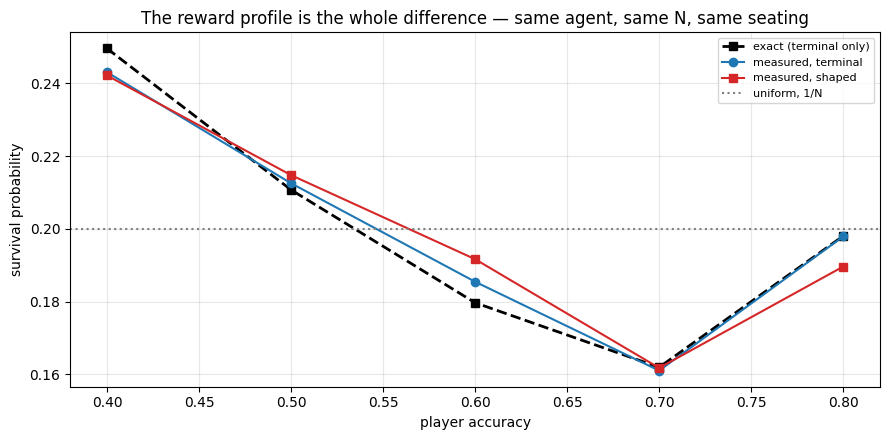

In [32]:
figure, axis = plt.subplots(figsize=(9, 4.5))
axis.plot(accuracies, [EXACT_RANKED[a] for a in accuracies], "ks--",
          label="exact (terminal only)", linewidth=2)
axis.plot(accuracies, [terminal_survival[a] for a in accuracies], "o-",
          color="tab:blue", label="measured, terminal")
axis.plot(accuracies, [shaped_survival[a] for a in accuracies], "s-",
          color="tab:red", label="measured, shaped")
axis.axhline(UNIFORM, color="grey", linestyle=":", label="uniform, 1/N")
axis.set_xlabel("player accuracy")
axis.set_ylabel("survival probability")
axis.set_title("The reward profile is the whole difference — same agent, same N, same seating")
axis.legend(fontsize=8)
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Targeting: what the two arms learned to do

In [33]:
print("%-10s %9s %9s %9s %9s %9s %10s"
      % ("reward", "0.4", "0.5", "0.6", "0.7", "0.8", "spread"))
targeting = {}
for reward_name in REWARDS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(reward_name, seed)])
    cells = []
    values = {}
    for accuracy in accuracies:
        rate, stronger, decisions = targeting_rate(combined, accuracy=accuracy)
        values[accuracy] = rate
        cells.append(format(rate, ".4f"))
    targeting[reward_name] = values
    spread = max(values.values()) - min(values.values())
    print("%-10s %9s %9s %9s %9s %9s %10.4f"
          % (reward_name, cells[0], cells[1], cells[2], cells[3], cells[4], spread))

reward           0.4       0.5       0.6       0.7       0.8     spread
terminal      0.9999    0.3790    0.3142    0.3745    0.9998     0.6857
shaped        0.9978    0.3734    0.3387    0.3987    1.0000     0.6613


The signatures step 5 built the instrument to tell apart, side by side.

In [34]:
UNDIFFERENTIATED_BAND = 0.10

u_shaped = {}
for reward_name in REWARDS:
    values = targeting[reward_name]
    extremes = min(values[0.4], values[0.8])
    middle = max(values[0.5], values[0.6], values[0.7])
    spread = max(values.values()) - min(values.values())
    near_half = True
    for accuracy in accuracies:
        if abs(values[accuracy] - 0.5) > UNDIFFERENTIATED_BAND:
            near_half = False
    u_shaped[reward_name] = extremes > middle

    print(reward_name + ":")
    print("    U-shaped (both extremes above every middle rank)?", u_shaped[reward_name])
    print("    every rank within %.2f of 0.5?                    %s"
          % (UNDIFFERENTIATED_BAND, near_half))
    print("    spread across ranks: %.4f" % spread)
    if u_shaped[reward_name]:
        print("    -> the equilibrium's shape")
    elif near_half:
        print("    -> discriminates on nothing")
    else:
        print("    -> neither signature; describe it rather than labelling it")
    print()

terminal:
    U-shaped (both extremes above every middle rank)? True
    every rank within 0.10 of 0.5?                    False
    spread across ranks: 0.6857
    -> the equilibrium's shape

shaped:
    U-shaped (both extremes above every middle rank)? True
    every rank within 0.10 of 0.5?                    False
    spread across ranks: 0.6613
    -> the equilibrium's shape



## And targeting against contraction

In [35]:
print("%-10s %11s %11s %11s   %s"
      % ("reward", "5 alive", "4 alive", "3 alive", "rises?"))
for reward_name in REWARDS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(reward_name, seed)])
    rows_alive = targeting_by_alive(combined)
    cells = []
    series = []
    for alive in [5, 4, 3]:
        if alive in rows_alive:
            cells.append(format(rows_alive[alive][0], ".4f"))
            series.append(rows_alive[alive][0])
        else:
            cells.append("no data")
            series.append(None)
    if None not in series and series[0] < series[1] < series[2]:
        mark = "yes"
    else:
        mark = "no"
    print("%-10s %11s %11s %11s   %s"
          % (reward_name, cells[0], cells[1], cells[2], mark))

print()
print("exact equilibrium: 0.40        0.50        1.00")

reward         5 alive     4 alive     3 alive   rises?
terminal        0.4038      0.5102      0.9763   yes
shaped          0.3997      0.5373      0.9667   yes

exact equilibrium: 0.40        0.50        1.00


## What this step establishes

In [36]:
print("held fixed : agent, N, seating, budget, hyperparameters, seeds")
print("moved      : the reward profile only (%d independent environment attribute)"
      % len(independent))
print()
print("weakest over uniform : terminal %.3f, shaped %.3f"
      % (terminal_weakest / UNIFORM, shaped_weakest / UNIFORM))
print("closest reference    : terminal %s, shaped %s"
      % (terminal_nearest, shaped_nearest))
print("U-shaped targeting   : terminal %s, shaped %s"
      % (u_shaped["terminal"], u_shaped["shaped"]))
print("matches equilibrium  : terminal %s, shaped %s"
      % (matches_equilibrium["terminal"], matches_equilibrium["shaped"]))
print()
print("The exact profile was applied to the terminal arm and REFUSED for the shaped one.")
print()
if present_under_both:
    print("1. Survival of the weakest survives the reward that produced it, so it is a")
    print("   property of the game. The control did its job.")
else:
    print("1. The effect does NOT appear under both profiles, so it cannot be reported as a")
    print("   property of the game on this evidence.")

if hunting_loses is None:
    print("2. No episode produced a sole survivor, so the measured half of this check has")
    print("   no data. The arithmetic bound is unaffected.")
elif hunting_loses:
    print("2. No non-winner out-earned any winner, measured, and the arithmetic bound says")
    print("   none could. So the hints do not invert what the game pays for.")
else:
    print("2. A non-winner DID out-earn a winner, so the hints can be followed away from")
    print("   winning and the shaped arm's numbers must be read accordingly.")

if same_policy:
    print("3. Both arms found the same policy (targeting %.4f apart), so the reward changed"
          % arm_distance)
    print("   the volume and not the behaviour. Contrast step 7, where one dial DID change")
    print("   the policy.")
else:
    print("3. The two arms found different policies (targeting %.4f apart), so the reward"
          % arm_distance)
    print("   changed the behaviour itself — the same kind of result step 7 produced from")
    print("   seating.")

held fixed : agent, N, seating, budget, hyperparameters, seeds
moved      : the reward profile only (1 independent environment attribute)

weakest over uniform : terminal 1.215, shaped 1.211
closest reference    : terminal neither, shaped neither
U-shaped targeting   : terminal True, shaped True
matches equilibrium  : terminal True, shaped True

The exact profile was applied to the terminal arm and REFUSED for the shaped one.

1. Survival of the weakest survives the reward that produced it, so it is a
   property of the game. The control did its job.
2. No non-winner out-earned any winner, measured, and the arithmetic bound says
   none could. So the hints do not invert what the game pays for.
3. Both arms found the same policy (targeting 0.0113 apart), so the reward changed
   the volume and not the behaviour. Contrast step 7, where one dial DID change
   the policy.


## Reproducibility

As in steps 6 and 7, **both** random streams are reset — the environment's and torch's —
because a trained policy samples its actions.

In [37]:
def measure_once():
    torch.manual_seed(7000)
    fixed_game = GruelEnv(n=N_PLAYERS, reward="shaped", seating=SEATING, seed=9000)
    records = play_episodes(fixed_game, make_agent_policy(models[("shaped", 0)]), 500)
    survival = survival_by_accuracy(records, accuracies)
    rate, stronger, decisions = targeting_rate(records)
    return (tuple(round(survival[a], 10) for a in accuracies),
            round(rate, 10), decisions)


first = measure_once()
second = measure_once()

print("first :", first)
print("second:", second)
print("identical:", first == second)

first : ((0.264, 0.196, 0.182, 0.18, 0.178), 0.6436420722, 2548)
second: ((0.264, 0.196, 0.182, 0.18, 0.178), 0.6436420722, 2548)
identical: True
